# Práctica 4b – Reconocimiento de caracteres en matrículas (OCR)
**Autoría:** Beatriz Chaves Marrero · Marcos Peña Armario

Compara un OCR clásico (**EasyOCR**) con un modelo visión-lenguaje (**SmolVLM**) sobre matrículas de UC3M-LP y aplica el OCR al pipeline de la práctica 4a (vídeo anotado + CSV con `texto_matricula`).

**Contenido**

1. Entorno, enlaces y datos
2. Comparativa OCR: muestra, métricas, EasyOCR, SmolVLM, formato de matrícula, tiempos y gráficos
3. Pipeline sobre el vídeo: seguimiento, matrículas, OCR, conteo, vídeo y CSV

**Cómo ejecutar:** entorno con GPU, y ejecutar todas las celdas en orden. El cuaderno descarga dataset, pesos y vídeo desde los enlaces de la sección 1 (deben ser públicos). Los pesos son los del detector de matrículas entrenado en `VC_P4a.ipynb`.

## 1. Entorno, enlaces y datos

In [ ]:
!pip install -q ultralytics easyocr gdown

In [ ]:
import os, re, csv, glob, math, time, random, collections, zipfile
import cv2, torch
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

DATASET_URL = "https://drive.google.com/file/d/1renkBiwUoSf1MaaG9ujI8COAHjhKdt5A/view?usp=sharing"
WEIGHTS_URL = "https://drive.google.com/file/d/1aX8Jv_dvw7f0s84GrwtZNvCrDgQMhnSt/view?usp=drive_link"   # best.pt del detector de matrículas (el mismo de VC_P4a)

RS_DS         = "/content/UC3M_RS"
PLATE_WEIGHTS = "/content/best.pt"

VIDEO_URL = "https://drive.google.com/file/d/1zwIS50Ht9E70OvhR8CXJVbXMiLTAM3V8/view?usp=drive_link"
VIDEO     = "/content/CO142.MP4"

def descargar(url, destino):
    if os.path.exists(destino):
        print("Ya existe:", destino); return
    if not url or url.startswith("PEGAR"):
        raise ValueError(f"Falta el enlace de descarga de {destino}")
    import gdown
    gdown.download(url, destino, quiet=False, fuzzy=True)

# Especificaciones de la máquina (para el README)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible")
print("Torch:", torch.__version__)
import platform
print("CPU:", platform.processor() or platform.machine(), "|", os.cpu_count(), "hilos")
print("RAM:", [l.split()[1] for l in open("/proc/meminfo") if l.startswith("MemTotal")][0], "kB")
print("Python:", platform.python_version())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
Torch: 2.14.1+cu130
CPU: x86_64 | 2 hilos
RAM: 13286932 kB
Python: 3.13.16


In [ ]:
if not os.path.exists(RS_DS):
    descargar(DATASET_URL, "/content/UC3M_RS.zip")
    with zipfile.ZipFile("/content/UC3M_RS.zip") as z:
        z.extractall("/content/")
descargar(WEIGHTS_URL, PLATE_WEIGHTS)

with open(f"{RS_DS}/ground_truth.csv", newline="", encoding="utf-8") as f:
    gt = list(csv.DictReader(f))

print("Filas:", len(gt))
print("Columnas:", list(gt[0].keys()))
print("Por partición:", collections.Counter(r["split"] for r in gt))
for r in gt[:3]:
    print(r)

Downloading...
From (original): https://drive.google.com/uc?id=1renkBiwUoSf1MaaG9ujI8COAHjhKdt5A
From (redirected): https://drive.google.com/uc?id=1renkBiwUoSf1MaaG9ujI8COAHjhKdt5A&confirm=t&uuid=0df36805-965f-4390-9592-9307854d541b
To: /content/UC3M_RS.zip
100%|██████████| 1.45G/1.45G [00:31<00:00, 46.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1aX8Jv_dvw7f0s84GrwtZNvCrDgQMhnSt
To: /content/best.pt
100%|██████████| 5.55M/5.55M [00:00<00:00, 14.9MB/s]

Filas: 2547
Columnas: ['split', 'image', 'plate_idx', 'text', 'lp_id_raw', 'n_hidden', 'x1', 'y1', 'x2', 'y2', 'img_w', 'img_h']
Por partición: Counter({'train': 1667, 'test': 491, 'val': 389})
{'split': 'train', 'image': '00001.jpg', 'plate_idx': '0', 'text': '074*C*V', 'lp_id_raw': 'AN-074*C*V', 'n_hidden': '2', 'x1': '2088', 'y1': '1406', 'x2': '3090', 'y2': '1873', 'img_w': '5184', 'img_h': '3888'}
{'split': 'train', 'image': '00002.jpg', 'plate_idx': '0', 'text': '*385*MW', 'lp_id_raw': 'AN-*385*MW', 'n_hidden': '2', 'x1': '2065', 'y1': '1320', 'x2': '2872', 'y2': '1621', 'img_w': '5184', 'img_h': '3888'}
{'split': 'train', 'image': '00002.jpg', 'plate_idx': '1', 'text': '38*3*PV', 'lp_id_raw': 'AN-38*3*PV', 'n_hidden': '2', 'x1': '4656', 'y1': '1439', 'x2': '5000', 'y2': '1632', 'img_w': '5184', 'img_h': '3888'}


## 2. Comparativa OCR clásico vs VLM
### 2.1 Muestra de matrículas de test
100 recortes aleatorios (semilla 42) de la partición de test con a lo sumo 2 caracteres censurados. Son los mismos para todos los métodos.

Matrículas de test con <= 2 censuradas: 491
Ancho del recorte (px): mín 28, mediana 175, máx 662


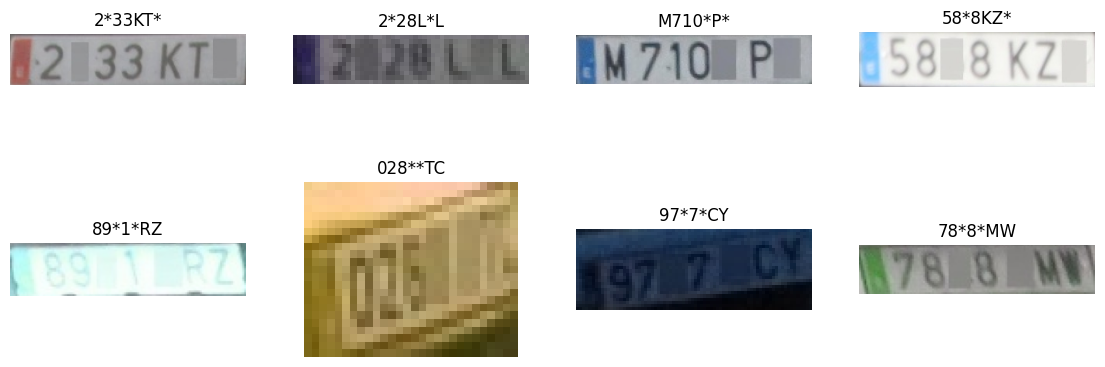

In [ ]:
N_MUESTRA  = 100
MAX_HIDDEN = 2      # solo matrículas con 2 o menos caracteres censurados
random.seed(42)

candidatas = [r for r in gt if r["split"] == "test" and int(r["n_hidden"]) <= MAX_HIDDEN]
print(f"Matrículas de test con <= {MAX_HIDDEN} censuradas: {len(candidatas)}")
muestra = random.sample(candidatas, N_MUESTRA)

recortes = []   # lista de (recorte BGR, texto de referencia)
for r in muestra:
    img = cv2.imread(f"{RS_DS}/test/images/{r['image']}")
    H, W = img.shape[:2]
    sx, sy = W / int(r["img_w"]), H / int(r["img_h"])
    x1, x2 = int(int(r["x1"]) * sx), int(int(r["x2"]) * sx)
    y1, y2 = int(int(r["y1"]) * sy), int(int(r["y2"]) * sy)
    recortes.append((img[y1:y2, x1:x2], r["text"]))

anchos = [c.shape[1] for c, _ in recortes]
print(f"Ancho del recorte (px): mín {min(anchos)}, mediana {int(np.median(anchos))}, máx {max(anchos)}")

# Muestra de 8 recortes con su texto de referencia
fig, axs = plt.subplots(2, 4, figsize=(14, 5))
for ax, (c, t) in zip(axs.ravel(), recortes[:8]):
    ax.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB)); ax.set_title(t); ax.axis("off")
plt.show()

### 2.2 Métricas
- **Estricta** (README): misma longitud y `*` como comodín.
- **Con alineado**: distancia de edición donde `*` casa con cualquier carácter o con ninguno (el OCR no puede leer un bloque gris).
- **CER**: errores de carácter sobre los caracteres visibles.

In [ ]:
def normalizar(s):
    """Mayúsculas y solo letras/dígitos (quita espacios, guiones, puntos)."""
    return "".join(ch for ch in s.upper() if ch.isalnum())

def coincide(gt, pred):
    """Métrica estricta del README: misma longitud, '*' comodín."""
    return len(gt) == len(pred) and all(g == '*' or g == p for g, p in zip(gt, pred))

def distancia(gt, pred):
    """Distancia de edición donde '*' en gt casa con cualquier carácter o con ninguno."""
    n, m = len(gt), len(pred)
    D = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        D[i][0] = D[i-1][0] + (0 if gt[i-1] == '*' else 1)
    for j in range(1, m + 1):
        D[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            sust = 0 if (gt[i-1] == '*' or gt[i-1] == pred[j-1]) else 1
            borrar = D[i-1][j] + (0 if gt[i-1] == '*' else 1)   # el OCR no leyó ese carácter
            insertar = D[i][j-1] + 1                             # el OCR añadió un carácter
            D[i][j] = min(D[i-1][j-1] + sust, borrar, insertar)
    return D[n][m]

def evaluar(nombre, preds, tiempos):
    refs = [t for _, t in recortes]
    preds = [normalizar(p) for p in preds]
    estricta  = sum(coincide(g, p) for g, p in zip(refs, preds)) / len(refs)
    tolerante = sum(distancia(g, p) == 0 for g, p in zip(refs, preds)) / len(refs)
    visibles  = sum(sum(ch != '*' for ch in g) for g in refs)
    cer       = sum(distancia(g, p) for g, p in zip(refs, preds)) / visibles
    print(f"{nombre}: acierto estricto {estricta:.1%} | acierto con alineado {tolerante:.1%} | "
          f"error de caracteres {cer:.1%} | tiempo medio {1000*np.mean(tiempos):.0f} ms "
          f"(mediana {1000*np.median(tiempos):.0f} ms)")
    return dict(nombre=nombre, estricta=estricta, tolerante=tolerante, cer=cer,
                t_medio=float(np.mean(tiempos)), t_mediana=float(np.median(tiempos)))

# Pruebas rápidas de las funciones
assert distancia("2*33KT*", "233KT") == 0        # el OCR salta los bloques grises
assert distancia("2*33KT*", "2X33KTY") == 0      # el OCR inventa un carácter en el hueco
assert coincide("2*33KT*", "2X33KTY") and not coincide("2*33KT*", "233KT")
assert distancia("97*7*CY", "9777CZ") == 1       # un error real (Y por Z)
print("Funciones de evaluación OK")

Funciones de evaluación OK


## Formato de matrícula y utilidades del pipeline
Una lectura de OCR solo se acepta si encaja en un formato real de matrícula española: **nueva** (4 dígitos + 3 consonantes, sin vocales ni Q/Ñ) o **antigua** (1-2 letras + 4 dígitos + 1-2 letras).
Si la lectura no encaja, se intentan corregir confusiones típicas de OCR según la posición (`O↔0`, `I↔1`, `S↔5`, `B↔8`…) con un máximo de sustituciones; si aun así no encaja, se descarta en lugar de guardarla en el CSV.

In [ ]:
CONSONANTES = "BCDFGHJKLMNPRSTVWXYZ"     # matrículas actuales: sin vocales, Ñ ni Q
MAX_SUST    = 2                          # máximo de caracteres que se permite "corregir" en una lectura

# Plantillas: D = dígito, C = consonante, L = letra cualquiera
FORMATOS = {"DDDDCCC": "nueva"}
for a in (1, 2):
    for b in (1, 2):
        FORMATOS["L" * a + "DDDD" + "L" * b] = "antigua"

RE_NUEVA_EN_TEXTO = re.compile(rf"\d{{4}}[{CONSONANTES}]{{3}}")

# Confusiones típicas de OCR según lo que la posición exige
A_DIGITO     = dict(O="0", Q="0", D="0", I="1", L="1", Z="2", S="5", G="6", B="8", T="7", A="4")
A_LETRA      = {"0": "O", "1": "I", "2": "Z", "4": "A", "5": "S", "6": "G", "7": "T", "8": "B"}
A_CONSONANTE = {"0": "D", "1": "L", "2": "Z", "5": "S", "6": "G", "7": "T", "8": "B",
                "O": "D", "U": "V", "E": "F", "I": "L"}

def clase_ok(ch, p):
    if ch == "*":                       # carácter censurado del ground truth: casa con todo
        return True
    if p == "D": return ch.isdigit()
    if p == "C": return ch in CONSONANTES
    return ch.isalpha()

def formato_valido(t):
    """'nueva', 'antigua' o None. Acepta '*' (comodín) para poder usarla también con el ground truth."""
    for pl, nombre in FORMATOS.items():
        if len(pl) == len(t) and all(clase_ok(ch, p) for ch, p in zip(t, pl)):
            return nombre
    return None

def forzar(t, plantilla):
    """Ajusta t a la plantilla corrigiendo confusiones típicas. Devuelve (texto, nº sustituciones) o None."""
    out, n = [], 0
    for ch, p in zip(t, plantilla):
        if clase_ok(ch, p):
            out.append(ch); continue
        mapa = A_DIGITO if p == "D" else (A_CONSONANTE if p == "C" else A_LETRA)
        if ch not in mapa:
            return None
        out.append(mapa[ch]); n += 1
    return "".join(out), n

def corregir_formato(txt, max_sust=MAX_SUST):
    """Devuelve (texto, formato). formato es None si no se pudo llevar a un formato de matrícula válido."""
    t = normalizar(txt)
    f = formato_valido(t)
    if f:
        return t, f
    candidatos = []
    for pl, nombre in FORMATOS.items():
        if len(pl) == len(t):
            r = forzar(t, pl)
            if r and r[1] <= max_sust:
                candidatos.append((r[1], nombre != "nueva", r[0], nombre))   # menos sustituciones; a igualdad, la nueva
    if candidatos:
        _, _, nuevo, nombre = min(candidatos)
        return nuevo, nombre
    m = RE_NUEVA_EN_TEXTO.search(t)          # secuencia larga que contiene una matrícula nueva completa
    if m:
        return m.group(), "nueva"
    return t, None

def votar(lecturas):
    """lecturas: lista de (texto_valido, peso). Voto por texto completo; con >=3 lecturas, voto carácter a carácter."""
    if not lecturas:
        return ""
    pesos = collections.Counter()
    for t, w in lecturas:
        pesos[t] += w
    mejor = max(pesos, key=pesos.get)
    if len(lecturas) < 3:
        return mejor
    mismos = [(t, w) for t, w in lecturas if len(t) == len(mejor)]
    res = ""
    for i in range(len(mejor)):
        c = collections.Counter()
        for t, w in mismos:
            c[t[i]] += w
        res += max(c, key=c.get)
    return res if formato_valido(res) else mejor

def recortar_placa(img, placa, pad=0.08):
    """Recorte de la matrícula con un margen (la caja de YOLO suele ser justa y puede cortar caracteres)."""
    H, W = img.shape[:2]
    bw, bh = placa[3] - placa[1], placa[4] - placa[2]
    x1, x2 = max(0, int(placa[1] - pad * bw)), min(W, int(placa[3] + pad * bw))
    y1, y2 = max(0, int(placa[2] - pad * bh)), min(H, int(placa[4] + pad * bh))
    return img[y1:y2, x1:x2]

# ---- Pruebas rápidas ----
assert formato_valido("1234BCD") == "nueva" and formato_valido("M7104PX") == "antigua"
assert formato_valido("1234AEI") is None and formato_valido("3326121") is None
assert corregir_formato("I234BCD") == ("1234BCD", "nueva")          # I -> 1
assert corregir_formato("1234BC0") == ("1234BCD", "nueva")          # 0 -> D
assert corregir_formato("ES1234BCD") == ("1234BCD", "nueva")        # secuencia larga con matrícula dentro
assert corregir_formato("3326121")[1] is None                       # imposible de encajar: se descarta
assert votar([("1234BCD", .9), ("1234BCD", .8), ("1284BCD", .5)]) == "1234BCD"
print("Funciones de formato OK")

# ¿Qué formatos tiene el ground truth? (los '*' son comodín)
cont = collections.Counter(formato_valido(r["text"]) or "ninguno" for r in gt)
print("Formato del ground truth:", dict(cont))
print("Ejemplos que no encajan:", [r["text"] for r in gt if not formato_valido(r["text"])][:10])

Funciones de formato OK
Formato del ground truth: {'nueva': 2446, 'antigua': 93, 'ninguno': 8}
Ejemplos que no encajan: ['R255*BC*', 'R95*1B*Y', 'TO018*8*', 'C5*48BS*', 'R22*2B*V', 'R22*2B*V', 'R*366BD*', 'BFMA*66*']


### 2.3 EasyOCR (OCR clásico)

In [ ]:
import easyocr

reader = easyocr.Reader(['es'], gpu=True)   # la primera vez descarga el modelo
LETRAS_NUM = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"

def leer_easyocr(crop):
    res = reader.readtext(crop, allowlist=LETRAS_NUM)
    res = sorted(res, key=lambda r: r[0][0][0])      # ordenar fragmentos de izquierda a derecha
    return "".join(texto for _, texto, _ in res)

leer_easyocr(recortes[0][0])   # calentamiento, no se mide

preds_easy, tiempos_easy = [], []
for crop, _ in recortes:
    t0 = time.perf_counter()
    preds_easy.append(leer_easyocr(crop))
    tiempos_easy.append(time.perf_counter() - t0)

resultados = {}
resultados["EasyOCR"] = evaluar("EasyOCR", preds_easy, tiempos_easy)

for (_, ref), p in list(zip(recortes, preds_easy))[:8]:
    print(f"ref {ref:10s} -> OCR {p}")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteEasyOCR: acierto estricto 7.0% | acierto con alineado 48.0% | error de caracteres 31.6% | tiempo medio 22 ms (mediana 21 ms)
ref 2*33KT*    -> OCR 2033KTL
ref 2*28L*L    -> OCR 
ref M710*P*    -> OCR M710P
ref 58*8KZ*    -> OCR 5808KZI
ref 89*1*RZ    -> OCR 5N
ref 028**TC    -> OCR 
ref 97*7*CY    -> OCR 
ref 78*8*MW    -> OCR 7850


### 2.4 Preprocesado para EasyOCR
Original, ampliar a ~100 px de alto, y ampliar + CLAHE.

In [ ]:
def preprocesar(crop, modo):
    if modo == "original":
        return crop
    h, w = crop.shape[:2]
    f = min(100 / h, 8)                                    # ampliar hasta ~100 px de alto (máx x8)
    img = cv2.resize(crop, (int(w * f), int(h * f)), interpolation=cv2.INTER_CUBIC)
    if modo == "clahe":
        gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        gris = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(gris)
        img = cv2.cvtColor(gris, cv2.COLOR_GRAY2BGR)
    return cv2.copyMakeBorder(img, 10, 10, 10, 10, cv2.BORDER_REPLICATE)

variantes = {"original": "EasyOCR (original)",
             "ampliar":  "EasyOCR (ampliar)",
             "clahe":    "EasyOCR (ampliar+CLAHE)"}

preds_variantes = {}
for modo, nombre in variantes.items():
    preds, tiempos = [], []
    for crop, _ in recortes:
        t0 = time.perf_counter()
        preds.append(leer_easyocr(preprocesar(crop, modo)))
        tiempos.append(time.perf_counter() - t0)
    preds_variantes[modo] = preds
    resultados[nombre] = evaluar(nombre, preds, tiempos)

EasyOCR (original): acierto estricto 7.0% | acierto con alineado 48.0% | error de caracteres 31.6% | tiempo medio 21 ms (mediana 20 ms)
EasyOCR (ampliar): acierto estricto 6.0% | acierto con alineado 46.0% | error de caracteres 26.2% | tiempo medio 48 ms (mediana 35 ms)
EasyOCR (ampliar+CLAHE): acierto estricto 6.0% | acierto con alineado 51.0% | error de caracteres 22.4% | tiempo medio 61 ms (mediana 36 ms)


### 2.5 SmolVLM (modelo visión-lenguaje)

In [ ]:
from transformers import AutoProcessor, AutoModelForImageTextToText
from PIL import Image

MODELO_VLM = "HuggingFaceTB/SmolVLM-Instruct"
processor = AutoProcessor.from_pretrained(MODELO_VLM)
vlm = AutoModelForImageTextToText.from_pretrained(
    MODELO_VLM, dtype=torch.float16, _attn_implementation="eager"
).to("cuda")

PROMPT = "What is the license plate number? Answer only with the characters of the plate, without spaces."

def leer_vlm(crop, prompt=PROMPT):
    img = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    mensajes = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    texto_chat = processor.apply_chat_template(mensajes, add_generation_prompt=True)
    inputs = processor(text=texto_chat, images=[img], return_tensors="pt")
    inputs = {k: (v.to("cuda", torch.float16) if v.is_floating_point() else v.to("cuda"))
              for k, v in inputs.items()}
    with torch.no_grad():
        salida = vlm.generate(**inputs, max_new_tokens=10, do_sample=False)
    return processor.batch_decode(salida[:, inputs["input_ids"].shape[1]:],
                                  skip_special_tokens=True)[0].strip()

# Calentamiento y prueba con 5 recortes (mismo preprocesado que EasyOCR: ampliar+CLAHE)
leer_vlm(preprocesar(recortes[0][0], "clahe"))
for crop, ref in recortes[:5]:
    t0 = time.perf_counter()
    p = leer_vlm(preprocesar(crop, "clahe"))
    dt = time.perf_counter() - t0
    print(f"ref {ref:10s} -> VLM '{p}'   ({1000*dt:.0f} ms)")

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/516 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.45k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.57k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

ref 2*33KT*    -> VLM '2133kt.'   (743 ms)
ref 2*28L*L    -> VLM '2128.'   (688 ms)
ref M710*P*    -> VLM 'M710P.'   (704 ms)
ref 58*8KZ*    -> VLM '5818kz'   (1127 ms)
ref 89*1*RZ    -> VLM '891rz'   (1082 ms)


In [ ]:
preds_vlm, tiempos_vlm = [], []
for crop, _ in recortes:
    t0 = time.perf_counter()
    preds_vlm.append(leer_vlm(preprocesar(crop, "clahe")))
    tiempos_vlm.append(time.perf_counter() - t0)

resultados["SmolVLM (ampliar+CLAHE)"] = evaluar("SmolVLM (ampliar+CLAHE)", preds_vlm, tiempos_vlm)

# Comparación directa con EasyOCR (misma entrada) en los primeros 10
preds_easy_clahe = preds_variantes["clahe"]
for (_, ref), pe, pv in list(zip(recortes, preds_easy_clahe, preds_vlm))[:10]:
    print(f"ref {ref:10s} | EasyOCR {normalizar(pe):10s} | SmolVLM {normalizar(pv)}")

SmolVLM (ampliar+CLAHE): acierto estricto 1.0% | acierto con alineado 84.0% | error de caracteres 5.2% | tiempo medio 1218 ms (mediana 1261 ms)
ref 2*33KT*    | EasyOCR 2133KTL    | SmolVLM 2133KT
ref 2*28L*L    | EasyOCR 2428       | SmolVLM 2128
ref M710*P*    | EasyOCR M7107P     | SmolVLM M710P
ref 58*8KZ*    | EasyOCR 58478KZI   | SmolVLM 5818KZ
ref 89*1*RZ    | EasyOCR 8941PZ     | SmolVLM 891RZ
ref 028**TC    | EasyOCR            | SmolVLM 026
ref 97*7*CY    | EasyOCR 970CY      | SmolVLM 977CY
ref 78*8*MW    | EasyOCR 78L8LMO    | SmolVLM 788MW
ref 050**DT    | EasyOCR 0500DT     | SmolVLM 050DT
ref 29*3*XX    | EasyOCR 298        | SmolVLM 293XX


### 2.6 ¿Ayuda el formato de matrícula?
Se prueba (a) corregir las lecturas con el formato español y (b) un prompt que describe el formato. Se reporta tal cual, aunque no mejore.

In [ ]:
# (a) Posprocesado por formato sobre las lecturas YA hechas (no vuelve a ejecutar ningún modelo)
def evaluar_post(nombre, preds, base):
    corr = [corregir_formato(p)[0] for p in preds]
    t = [resultados[base]["t_medio"]] * len(recortes)      # el coste del regex es despreciable
    return evaluar(nombre, corr, t)

resultados["EasyOCR (ampliar+CLAHE) + formato"] = evaluar_post(
    "EasyOCR (ampliar+CLAHE) + formato", preds_variantes["clahe"], "EasyOCR (ampliar+CLAHE)")
resultados["SmolVLM (ampliar+CLAHE) + formato"] = evaluar_post(
    "SmolVLM (ampliar+CLAHE) + formato", preds_vlm, "SmolVLM (ampliar+CLAHE)")

# (b) Prompt que describe el formato de las matrículas españolas
PROMPT_FMT = ("The image shows a Spanish license plate: either 4 digits followed by 3 consonant letters, "
              "or 1-2 letters, 4 digits and 1-2 letters. Answer only with the characters of the plate, no spaces.")

preds_v2, tiempos_v2 = [], []
for crop, _ in recortes:
    t0 = time.perf_counter()
    preds_v2.append(leer_vlm(preprocesar(crop, "clahe"), PROMPT_FMT))
    tiempos_v2.append(time.perf_counter() - t0)

resultados["SmolVLM (prompt formato)"] = evaluar("SmolVLM (prompt formato)", preds_v2, tiempos_v2)
resultados["SmolVLM (prompt formato) + formato"] = evaluar_post(
    "SmolVLM (prompt formato) + formato", preds_v2, "SmolVLM (prompt formato)")

# Lecturas que quedarían fuera del formato (son las que antes acababan en el CSV como basura)
for nombre, preds in [("prompt base", preds_vlm), ("prompt formato", preds_v2)]:
    largas = sum(len(normalizar(p)) > 8 for p in preds)
    print(f"SmolVLM {nombre}: {largas} lecturas de más de 8 caracteres")

EasyOCR (ampliar+CLAHE) + formato: acierto estricto 6.0% | acierto con alineado 45.0% | error de caracteres 25.8% | tiempo medio 61 ms (mediana 61 ms)
SmolVLM (ampliar+CLAHE) + formato: acierto estricto 1.0% | acierto con alineado 83.0% | error de caracteres 5.6% | tiempo medio 1218 ms (mediana 1218 ms)
SmolVLM (prompt formato): acierto estricto 1.0% | acierto con alineado 71.0% | error de caracteres 12.0% | tiempo medio 1243 ms (mediana 1272 ms)
SmolVLM (prompt formato) + formato: acierto estricto 1.0% | acierto con alineado 70.0% | error de caracteres 12.4% | tiempo medio 1243 ms (mediana 1243 ms)
SmolVLM prompt base: 0 lecturas de más de 8 caracteres
SmolVLM prompt formato: 0 lecturas de más de 8 caracteres


### 2.7 Tiempos (mismas condiciones)
Los tres métodos se miden con la misma función, los mismos 100 recortes, un calentamiento previo y 3 pasadas (se usa la mediana).

In [ ]:
def pasadas(funcion, n=3):
    medias = []
    for _ in range(n):
        ts = []
        for crop, _ in recortes:
            t0 = time.perf_counter(); funcion(crop); ts.append(time.perf_counter() - t0)
        medias.append(float(np.mean(ts)))
    return medias

f_easy = lambda c: leer_easyocr(preprocesar(c, "clahe"))
f_vlm  = lambda c: leer_vlm(preprocesar(c, "clahe"))
f_easy(recortes[0][0]); f_vlm(recortes[0][0])      # calentamiento

f_orig = lambda c: leer_easyocr(c)
f_orig(recortes[0][0])
med_orig, med_easy, med_vlm = pasadas(f_orig), pasadas(f_easy), pasadas(f_vlm)
tiempo_final = {"EasyOCR original": 1000 * float(np.median(med_orig)),
                "EasyOCR": 1000 * float(np.median(med_easy)),
                "SmolVLM": 1000 * float(np.median(med_vlm))}
print("EasyOCR original pasadas (ms):", [round(1000 * t) for t in med_orig])
print("EasyOCR pasadas (ms):", [round(1000 * t) for t in med_easy])
print("SmolVLM pasadas (ms):", [round(1000 * t) for t in med_vlm])
print("Mediana:", {k: round(v) for k, v in tiempo_final.items()})
print("Factor de lentitud:", round(tiempo_final["SmolVLM"] / tiempo_final["EasyOCR"]), "x")

EasyOCR original pasadas (ms): [28, 20, 20]
EasyOCR pasadas (ms): [26, 25, 32]
SmolVLM pasadas (ms): [1275, 1271, 1268]
Mediana: {'EasyOCR original': 20, 'EasyOCR': 26, 'SmolVLM': 1271}
Factor de lentitud: 50 x


### 2.8 Gráficos

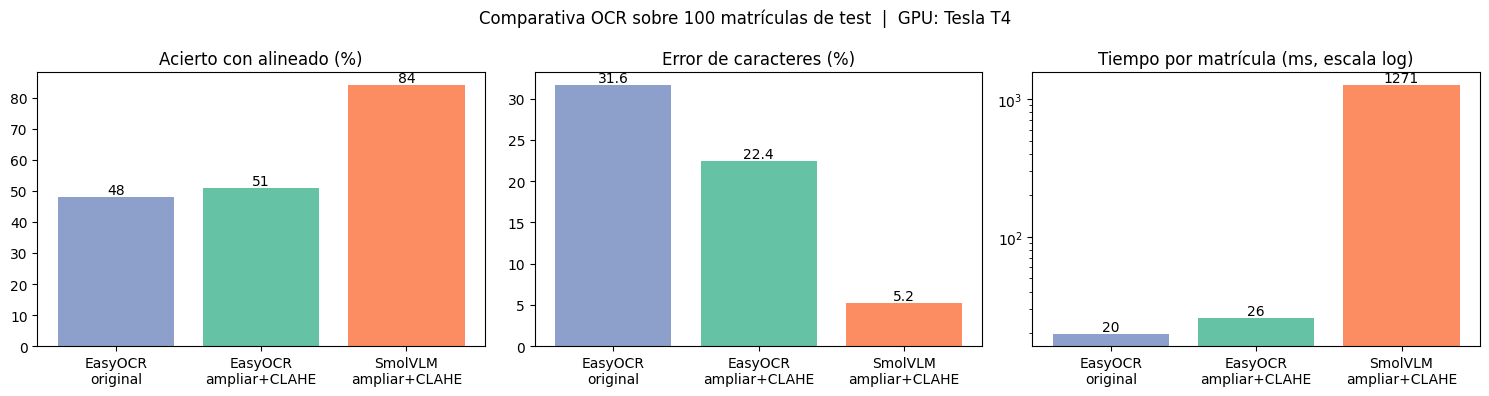

In [ ]:
nombres = ["EasyOCR (original)", "EasyOCR (ampliar+CLAHE)", "SmolVLM (ampliar+CLAHE)"]
etiquetas = ["EasyOCR\noriginal", "EasyOCR\nampliar+CLAHE", "SmolVLM\nampliar+CLAHE"]
acierto = [100 * resultados[n]["tolerante"] for n in nombres]
cer     = [100 * resultados[n]["cer"] for n in nombres]
tiempo  = [tiempo_final["EasyOCR original"], tiempo_final["EasyOCR"], tiempo_final["SmolVLM"]]
colores = ["#8da0cb", "#66c2a5", "#fc8d62"]

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, vals, tit, fmt in [(axs[0], acierto, "Acierto con alineado (%)", "{:.0f}"),
                           (axs[1], cer, "Error de caracteres (%)", "{:.1f}"),
                           (axs[2], tiempo, "Tiempo por matrícula (ms, escala log)", "{:.0f}")]:
    barras = ax.bar(etiquetas, vals, color=colores)
    ax.set_title(tit)
    for b, v in zip(barras, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom")
axs[2].set_yscale("log")
fig.suptitle(f"Comparativa OCR sobre {len(recortes)} matrículas de test  |  GPU: {torch.cuda.get_device_name(0)}")
plt.tight_layout()
plt.savefig("/content/comparativa_ocr.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Pipeline sobre el vídeo
Mismo procedimiento que `VC_P4a.ipynb`: la matrícula se busca dentro del recorte de cada vehículo (`imgsz=640`, `conf=0.25`), la clase de cada ID es la más frecuente y solo se cuentan IDs presentes en al menos `MIN_FRAMES` fotogramas. Se añade el OCR: varias lecturas por vehículo, solo se aceptan las que encajan en un formato de matrícula y se combinan por votación.
### 3.1 Vídeo y modelos

In [ ]:
descargar(VIDEO_URL, VIDEO)

track_model = YOLO('yolo11n.pt')
plate_model = YOLO(PLATE_WEIGHTS)
classNames = {0: "person", 1: "bicycle", 2: "car", 3: "motorbike", 5: "bus", 7: "truck"}
clases_interes = list(classNames.keys())

vid = cv2.VideoCapture(VIDEO)
print(f"{int(vid.get(3))}x{int(vid.get(4))}, {vid.get(5):.1f} fps, {int(vid.get(7))} fotogramas")
vid.release()

Downloading...
From (original): https://drive.google.com/uc?id=1zwIS50Ht9E70OvhR8CXJVbXMiLTAM3V8
From (redirected): https://drive.google.com/uc?id=1zwIS50Ht9E70OvhR8CXJVbXMiLTAM3V8&confirm=t&uuid=21b91220-be80-4ac0-aa6a-db46f59f34e7
To: /content/CO142.MP4
100%|██████████| 201M/201M [00:04<00:00, 43.7MB/s]


1920x1080, 25.0 fps, 2832 fotogramas


### 3.2 Pasada 1: detección, seguimiento, matrículas y OCR

In [ ]:
# ---- Configuración ----
PROMPT_ACTIVO   = PROMPT       # el prompt con formato empeoró los resultados (sección 2.6), se usa el base
OCR_FUNC        = lambda crop: leer_vlm(preprocesar(crop, "clahe"), PROMPT_ACTIVO)   # o leer_easyocr(preprocesar(crop, "clahe"))
MAX_FRAMES      = None         # None = vídeo completo (poner 300 para pruebas rápidas)
VEHICULOS       = {2, 3, 5, 7}
CONF_PLACA      = 0.25         # igual que en VC_P4a
IMGSZ_PLACA     = 640          # igual que en VC_P4a (la matrícula se busca dentro del recorte del vehículo)
MIN_FRAMES      = 25           # un ID cuenta en el conteo si aparece al menos en tantos fotogramas
PAD_PLACA       = 0.08         # margen alrededor de la matrícula antes del OCR
MIN_ANCHO_PLACA = 50           # px mínimos de ancho de la matrícula para intentar leerla
RATIO_MIN, RATIO_MAX = 1.5, 7.0    # ancho/alto razonable de una matrícula
OBJETIVO_VALIDAS = 3           # se deja de leer un vehículo al reunir este nº de lecturas válidas
MAX_INTENTOS    = 8            # lecturas máximas (válidas o no) por vehículo
SEPARACION      = 8            # fotogramas mínimos entre lecturas del mismo vehículo
VIDEO_OUT = "/content/salida_p4.mp4"
CSV_OUT   = "/content/resultado.csv"
CSV_VEH   = "/content/resumen_vehiculos.csv"

track_model = YOLO('yolo11n.pt')      # reinicia el tracker
vid = cv2.VideoCapture(VIDEO)
fps = vid.get(cv2.CAP_PROP_FPS)
W = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))

registros      = collections.defaultdict(list)    # fotograma -> detecciones
validas        = collections.defaultdict(list)    # id -> [(fotograma, texto válido, confianza de la matrícula)]
descartadas    = collections.defaultdict(list)    # id -> lecturas que no encajaron en ningún formato
intentos       = collections.defaultdict(int)
ultima_lectura = {}
tiempos_ocr    = []
fotograma = 0

while True:
    ret, img = vid.read()
    if not ret or (MAX_FRAMES is not None and fotograma >= MAX_FRAMES):
        break

    res = track_model.track(img, persist=True, classes=clases_interes, device=0, verbose=False)[0]
    for box in res.boxes:
        if box.id is None:
            continue
        cls = int(box.cls[0]); tid = int(box.id[0])
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
        reg = dict(tid=tid, cls=classNames[cls], conf=round(float(box.conf[0]), 2),
                   caja=(x1, y1, x2, y2), placa=None)

        # Matrícula buscada dentro del recorte del vehículo (igual que en VC_P4a)
        if cls in VEHICULOS and (x2 - x1) > 40 and (y2 - y1) > 40:
            rp = plate_model(img[y1:y2, x1:x2], imgsz=IMGSZ_PLACA, conf=CONF_PLACA, device=0, verbose=False)[0]
            if len(rp.boxes):
                b = rp.boxes[int(rp.boxes.conf.argmax())]
                px1, py1, px2, py2 = [int(v) for v in b.xyxy[0]]
                placa = (round(float(b.conf[0]), 2), x1 + px1, y1 + py1, x1 + px2, y1 + py2)
                reg["placa"] = placa

                # OCR (solo si la matrícula es legible y han pasado suficientes fotogramas desde la última lectura)
                ancho, alto = placa[3] - placa[1], placa[4] - placa[2]
                if (len(validas[tid]) < OBJETIVO_VALIDAS
                        and intentos[tid] < MAX_INTENTOS
                        and fotograma - ultima_lectura.get(tid, -999) >= SEPARACION
                        and ancho >= MIN_ANCHO_PLACA
                        and RATIO_MIN <= ancho / max(alto, 1) <= RATIO_MAX):
                    t0 = time.perf_counter()
                    crudo = OCR_FUNC(recortar_placa(img, placa, PAD_PLACA))
                    tiempos_ocr.append(time.perf_counter() - t0)
                    ultima_lectura[tid] = fotograma; intentos[tid] += 1
                    txt, fmt = corregir_formato(crudo)
                    if fmt:
                        validas[tid].append((fotograma, txt, placa[0]))
                    else:
                        descartadas[tid].append(normalizar(crudo))
        registros[fotograma].append(reg)
    fotograma += 1
vid.release()
n_proc = fotograma
print("Pasada 1 terminada:", n_proc, "fotogramas |", len(tiempos_ocr), "lecturas OCR | "
      f"{1000 * np.mean(tiempos_ocr):.0f} ms por lectura")

Pasada 1 terminada: 2832 fotogramas | 82 lecturas OCR | 1259 ms por lectura


### 3.3 Pasada 2: conteo, vídeo de salida y CSV

In [ ]:
# ---- Clase definitiva de cada ID (la más frecuente) y conteo (mismos criterios que VC_P4a) ----
votos = collections.defaultdict(collections.Counter)
for regs in registros.values():
    for r in regs:
        votos[r["tid"]][r["cls"]] += 1
clase_final = {tid: v.most_common(1)[0][0] for tid, v in votos.items()}
n_frames    = {tid: sum(v.values()) for tid, v in votos.items()}
estables    = {tid for tid, n in n_frames.items() if n >= MIN_FRAMES}

primer_frame, ultimo_frame, con_placa, primer_placa = {}, {}, set(), {}
for fr in sorted(registros):
    for r in registros[fr]:
        primer_frame.setdefault(r["tid"], fr)
        ultimo_frame[r["tid"]] = fr
        if r["placa"]:
            con_placa.add(r["tid"])
            primer_placa.setdefault(r["tid"], fr)

def texto_hasta(tid, fr):
    """Texto votado con las lecturas válidas obtenidas hasta el fotograma fr."""
    return votar([(t, w) for f, t, w in validas[tid] if f <= fr])

# ---- Pasada 2: vídeo de salida (resolución original) y CSV ----
vid = cv2.VideoCapture(VIDEO)
writer = cv2.VideoWriter(VIDEO_OUT, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
filas = []
for fr in range(n_proc):
    ret, img = vid.read()
    if not ret:
        break
    for r in registros.get(fr, []):
        tid = r["tid"]; nombre = clase_final[tid]
        x1, y1, x2, y2 = r["caja"]; placa = r["placa"]
        texto = texto_hasta(tid, fr) if placa else ""

        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img, f"{tid} {nombre}", (x1, max(20, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
        if placa:
            cv2.rectangle(img, (placa[1], placa[2]), (placa[3], placa[4]), (0, 0, 255), 3)
            cv2.putText(img, texto or "plate", (placa[1], max(20, placa[2] - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)

        filas.append([fr, nombre, r["conf"], tid, x1, y1, x2, y2,
                      "si" if placa else "no",
                      placa[0] if placa else "", *(placa[1:] if placa else ["", "", "", ""]), texto])

    # Contador: IDs estables ya vistos, por clase mayoritaria
    cuenta = collections.Counter(clase_final[t] for t in estables if primer_frame[t] <= fr)
    cuenta["plate"] = sum(1 for t, f0 in primer_placa.items() if t in estables and f0 <= fr)
    y = 40
    for nombre, n in cuenta.items():
        cv2.putText(img, f"{nombre}: {n}", (20, y), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2); y += 35
    writer.write(img)
vid.release(); writer.release()

cabecera = ["fotograma", "tipo_objeto", "confianza", "identificador_tracking", "x1", "y1", "x2", "y2",
            "matricula", "confianza_matricula", "mx1", "my1", "mx2", "my2", "texto_matricula"]
with open(CSV_OUT, "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f); wr.writerow(cabecera); wr.writerows(filas)

texto_final = {tid: votar([(t, w) for _, t, w in validas[tid]]) for tid in n_frames}
with open(CSV_VEH, "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f)
    wr.writerow(["identificador_tracking", "tipo_objeto", "primer_fotograma", "ultimo_fotograma",
                 "n_fotogramas", "estable", "matricula_detectada", "n_lecturas_validas", "texto_matricula"])
    for tid in sorted(n_frames):
        wr.writerow([tid, clase_final[tid], primer_frame[tid], ultimo_frame[tid], n_frames[tid],
                     "si" if tid in estables else "no", "si" if tid in con_placa else "no",
                     len(validas[tid]), texto_final[tid]])

# ---- Resumen ----
print(f"Fotogramas procesados: {n_proc} | filas en el CSV: {len(filas)}")
print("IDs totales por clase:   ", dict(collections.Counter(clase_final.values())))
print(f"IDs estables (>= {MIN_FRAMES} fotogramas):", dict(collections.Counter(clase_final[t] for t in estables)))
veh_estables = sorted(t for t in estables if clase_final[t] in {classNames[c] for c in VEHICULOS})
con_pl  = [t for t in veh_estables if t in con_placa]
con_txt = [t for t in con_pl if texto_final[t]]
print(f"Vehículos estables: {len(veh_estables)} -> con matrícula detectada: {len(con_pl)} "
      f"-> con texto leído: {len(con_txt)} (sin lectura válida: {len(con_pl) - len(con_txt)})")
print()
for tid in con_pl:
    print(f"{tid:4d} {clase_final[tid]:10s} válidas={[t for _, t, _ in validas[tid]]} "
          f"descartadas={descartadas[tid]} -> {texto_final[tid] or '(sin lectura válida)'}")

Fotogramas procesados: 2832 | filas en el CSV: 9725
IDs totales por clase:    {'bus': 1, 'car': 40, 'person': 16, 'bicycle': 1, 'motorbike': 1}
IDs estables (>= 25 fotogramas): {'bus': 1, 'car': 38, 'person': 13}
Vehículos estables: 39 -> con matrícula detectada: 31 -> con texto leído: 22 (sin lectura válida: 9)

   1 bus        válidas=[] descartadas=['3226', '332621', '3326'] -> (sin lectura válida)
   4 car        válidas=[] descartadas=['5555', '5555', '5555'] -> (sin lectura válida)
   8 car        válidas=[] descartadas=['5555', '152222222'] -> (sin lectura válida)
   9 car        válidas=['4213LFG', '3713LKC', '3713LKC'] descartadas=[] -> 3713LKC
  10 car        válidas=['5776SFP'] descartadas=['57665505'] -> 5776SFP
  11 car        válidas=['G7857S'] descartadas=['3578'] -> G7857S
  12 car        válidas=['0848MCG', '0848MCG'] descartadas=['0845MC', '5555'] -> 0848MCG
  13 car        válidas=['S5555S'] descartadas=['3333'] -> S5555S
  15 car        válidas=['6713MCR', '6713HFR'

### 3.4 Visualización y descarga

In [ ]:
import subprocess, base64
from IPython.display import HTML, display
from google.colab import files

subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", VIDEO_OUT, "-vcodec", "libx264",
                "-pix_fmt", "yuv420p", "/content/salida_p4_h264.mp4"], check=True)
mb = os.path.getsize("/content/salida_p4_h264.mp4") / 1e6
print(f"Vídeo: {mb:.1f} MB")
if mb < 25:
    data = base64.b64encode(open("/content/salida_p4_h264.mp4", "rb").read()).decode()
    display(HTML(f'<video width="960" controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))
else:
    files.download("/content/salida_p4_h264.mp4")
files.download(CSV_OUT); files.download(CSV_VEH); files.download("/content/comparativa_ocr.png")

Vídeo: 56.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>